# Tanzania Waterpoint Functionality — Exploratory Data Analysis (EDA)

Predicting whether a rural waterpoint is **functional**, **non functional**, or **functional needs repair** from the DrivenData *Pump it Up: Data Mining the Water Table* competition register (**59,400 waterpoints × 40 features**).

---

### Notebook Architecture & Workflow
This notebook presents an end-to-end, rigorous exploratory data analysis designed to transition directly into modeling:
1. **0. Setup & Global Configuration**: Reproducible environment, visual palettes, and metrics registry.
2. **1. Data Ingestion & Structural Audit**: Schema verification, joins, and data dictionary taxonomy.
3. **2. Core Statistical & Plotting Helpers**: Bias-corrected Cramér's V, class composition, and plotting utilities.
4. **3. Target Variable Distribution**: Class breakdown, baseline benchmarks, and severe class imbalance.
5. **4. Data Quality & Masked Anomalies**: Explicit missingness, disguised sentinel zeros, and 1:1 hierarchical redundancies.
6. **5. Key Predictive Drivers**: Global categorical association ranking, water quantity dominance, and management variables.
7. **6. Numeric Feature Diagnostics**: Age derivation, outlier checks, repeated data entry diagnostics, and ANOVA vs. Mutual Information.
9. **7. Geospatial Analysis**: Regional performance disparities and high-resolution spatial boundary mapping.



## 0. Setup & Global Configuration

In this step, we configure the runtime environment:
- **Environment Detection**: Detect whether execution is occurring in Google Colab (`IN_COLAB`) or a local Jupyter kernel.
- **Styling & Aesthetics**: Set a crisp Seaborn theme (`whitegrid`) and Matplotlib DPI to ensure high-resolution figure outputs.
- **Color Palette Consistency**: Define standardized hex color mappings (`PALETTE` and darkened `SCATTER`) across all three target classes to maintain visual cohesion throughout the notebook:
  - `functional`: `#2A9D8F` (Teal)
  - `functional needs repair`: `#E9C46A` (Amber)
  - `non functional`: `#E76F51` (Coral)
- **Global Metrics Registry**: Initialize the `STATS` dictionary, which records exact numerical findings from every section for programmatic inspection and report generation.


In [1]:
!pip install -q basemap basemap-data
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.feature_selection import f_classif, mutual_info_classif
from matplotlib.colors import ListedColormap
from mpl_toolkits.basemap import Basemap, maskoceans
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
import matplotlib.patheffects as pe


[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: C:\Users\Windows 10\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip
c:\Users\Windows 10\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## 1. Data Ingestion & Initial Structural Inspection

### 1.1 Loading and Merging Datasets
The competition separates features (`train_values.csv`) from ground-truth labels (`train_labels.csv`).
- `find_csvs()` automatically searches across common local paths and Colab mounts.
- We perform an inner merge on primary key `id`.
- Rigorous sanity checks verify that row counts match across both files (`STATS["merge_ok"]`) and identify any duplicate IDs or duplicate records.


In [2]:
values = pd.read_csv(r"C:\Users\Windows 10\Desktop\Coding\Data mining\Dataset\Raw\train_values.csv")
labels = pd.read_csv(r"C:\Users\Windows 10\Desktop\Coding\Data mining\Dataset\Raw\train_labels.csv")
df = values.merge(labels, on="id")

if "STATS" not in globals():
      STATS = {}
STATS["shape"] = {"rows": len(df), "cols": df.shape[1]}
STATS["merge_ok"] = len(df) == len(values) == len(labels)
STATS["duplicate_ids"] = int(df["id"].duplicated().sum())
STATS["duplicate_rows_excl_id"] = int(df.drop(columns=["id"]).duplicated().sum())

print(f"values {values.shape} + labels {labels.shape} -> merged {df.shape}")
print(f"clean join: {STATS['merge_ok']}  duplicate rows (ignoring id): "
      f"{STATS['duplicate_rows_excl_id']}")
df.head(3)


values (59400, 40) + labels (59400, 2) -> merged (59400, 41)
clean join: True  duplicate rows (ignoring id): 36


,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,...,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,...,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,...,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe,functional


### 1.2 Inspecting Schema and Data Types
Examining the merged dataframe with `df.info()`.
> **Key Observations on Data Types:**
> - `construction_year` and `region_code` are loaded as integers rather than temporal/categorical representations.
> - `public_meeting` and `permit` have object dtype due to mixed booleans and missing values.
> - The total dataframe comprises 41 columns and ~18.6 MB of memory.


In [3]:
df.info(show_counts=True)


<class 'pandas.DataFrame'>
RangeIndex: 59400 entries, 0 to 59399
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     59400 non-null  int64  
 1   amount_tsh             59400 non-null  float64
 2   date_recorded          59400 non-null  str    
 3   funder                 55763 non-null  str    
 4   gps_height             59400 non-null  int64  
 5   installer              55745 non-null  str    
 6   longitude              59400 non-null  float64
 7   latitude               59400 non-null  float64
 8   wpt_name               59398 non-null  str    
 9   num_private            59400 non-null  int64  
 10  basin                  59400 non-null  str    
 11  subvillage             59029 non-null  str    
 12  region                 59400 non-null  str    
 13  region_code            59400 non-null  int64  
 14  district_code          59400 non-null  int64  
 15  lga          

### 1.3 Baseline Missing Value Audit
Running a standard `df.isnull().sum()` check.
Notice that **33 out of 41 columns report 0 missing values**. However, as demonstrated in Section 4, this is deceptive: numerous numerical columns encode missing values using disguised sentinels (such as `0` and `1`).


In [4]:
nulls = df.isnull().sum()
print(nulls.to_string())
print(f"\n{(nulls == 0).sum()} of {len(nulls)} columns report zero missing")


id                           0
amount_tsh                   0
date_recorded                0
funder                    3637
gps_height                   0
installer                 3655
longitude                    0
latitude                     0
wpt_name                     2
num_private                  0
basin                        0
subvillage                 371
region                       0
region_code                  0
district_code                0
lga                          0
ward                         0
population                   0
public_meeting            3334
recorded_by                  0
scheme_management         3878
scheme_name              28810
permit                    3056
construction_year            0
extraction_type              0
extraction_type_group        0
extraction_type_class        0
management                   0
management_group             0
payment                      0
payment_type                 0
water_quality                0
quality_

### 1.4 Data Dictionary & Domain Taxonomy
To understand the relationships between features, we map the official competition metadata:
- We group the 39 features into 7 functional semantic categories:
  - `record-keeping`: Administrative logging details
  - `where it is`: Spatial coordinates and administrative hierarchy
  - `who built it, and when`: Construction and funding entities
  - `who runs it, and on what terms`: Operational management and payment models
  - `the water itself`: Quantity, quality, and water source characteristics
  - `the hardware`: Extraction mechanisms and physical waterpoint structures
  - `who it serves`: Population estimates
- We also detect **shared descriptions** in the metadata itself, revealing that official documentation defines multiple granularities with identical descriptions.


In [5]:
DICT = {
    "amount_tsh": "Total static head (amount water available to waterpoint)",
    "date_recorded": "The date the row was entered",
    "funder": "Who funded the well",
    "gps_height": "Altitude of the well",
    "installer": "Organization that installed the well",
    "longitude": "GPS coordinate",
    "latitude": "GPS coordinate",
    "wpt_name": "Name of the waterpoint if there is one",
    "num_private": "",  # no description is given
    "basin": "Geographic water basin",
    "subvillage": "Geographic location",
    "region": "Geographic location",
    "region_code": "Geographic location (coded)",
    "district_code": "Geographic location (coded)",
    "lga": "Geographic location",
    "ward": "Geographic location",
    "population": "Population around the well",
    "public_meeting": "True/False",
    "recorded_by": "Group entering this row of data",
    "scheme_management": "Who operates the waterpoint",
    "scheme_name": "Who operates the waterpoint",
    "permit": "If the waterpoint is permitted",
    "construction_year": "Year the waterpoint was constructed",
    "extraction_type": "The kind of extraction the waterpoint uses",
    "extraction_type_group": "The kind of extraction the waterpoint uses",
    "extraction_type_class": "The kind of extraction the waterpoint uses",
    "management": "How the waterpoint is managed",
    "management_group": "How the waterpoint is managed",
    "payment": "What the water costs",
    "payment_type": "What the water costs",
    "water_quality": "The quality of the water",
    "quality_group": "The quality of the water",
    "quantity": "The quantity of water",
    "quantity_group": "The quantity of water",
    "source": "The source of the water",
    "source_type": "The source of the water",
    "source_class": "The source of the water",
    "waterpoint_type": "The kind of waterpoint",
    "waterpoint_type_group": "The kind of waterpoint",
}

GROUPS = {
    "record-keeping": ["date_recorded", "recorded_by", "wpt_name", "num_private"],
    "where it is": ["latitude", "longitude", "gps_height", "basin", "region",
                    "region_code", "district_code", "lga", "ward", "subvillage"],
    "who built it, and when": ["funder", "installer", "construction_year"],
    "who runs it, and on what terms": [
        "scheme_management", "scheme_name", "management", "management_group",
        "permit", "public_meeting", "payment", "payment_type"],
    "the water itself": ["quantity", "quantity_group", "water_quality",
                         "quality_group", "source", "source_type",
                         "source_class", "amount_tsh"],
    "the hardware": ["extraction_type", "extraction_type_group",
                     "extraction_type_class", "waterpoint_type",
                     "waterpoint_type_group"],
    "who it serves": ["population"],
}

assert {c for v in GROUPS.values() for c in v} == set(DICT)

LABELS = {"functional": "operational and no repairs needed",
          "functional needs repair": "operational, but needs repairs",
          "non functional": "not operational"}

for g, cols in GROUPS.items():
    print(f"{g:34s} {len(cols):>2}  {', '.join(cols)}")
print()

# Note how little the descriptions separate the hierarchy columns:
dup = pd.Series(DICT).to_frame("description")
dup["shared_with"] = dup["description"].map(
    lambda d: ", ".join(k for k in DICT if DICT[k] == d and d))
print("Columns sharing an identical official description — the redundancy of "
      "§4.3 is in the dictionary itself, not just in the data:\n")
for d, grp in dup[dup.description != ""].groupby("description"):
    if len(grp) > 1:
        print(f"  {list(grp.index)}\n     -> \"{d}\"")


record-keeping                      4  date_recorded, recorded_by, wpt_name, num_private
where it is                        10  latitude, longitude, gps_height, basin, region, region_code, district_code, lga, ward, subvillage
who built it, and when              3  funder, installer, construction_year
who runs it, and on what terms      8  scheme_management, scheme_name, management, management_group, permit, public_meeting, payment, payment_type
the water itself                    8  quantity, quantity_group, water_quality, quality_group, source, source_type, source_class, amount_tsh
the hardware                        5  extraction_type, extraction_type_group, extraction_type_class, waterpoint_type, waterpoint_type_group
who it serves                       1  population

Columns sharing an identical official description — the redundancy of §4.3 is in the dictionary itself, not just in the data:

  ['longitude', 'latitude']
     -> "GPS coordinate"
  ['subvillage', 'region', 'lga', 'war

## 2. Core Statistical & Plotting Helper Utilities

Before diving into feature distributions, we define four reusable analytical functions:
1. `cramers_v(a, b)`:
   - Computes **bias-corrected Cramér's V** (Bergsma, 2013).
   - Standard $\chi^2$ and raw Cramér's V artificially inflate when contingency tables have many categories (which here range from 2 up to 21 categories).
   - The bias correction adjusts degrees of freedom:
     $$\tilde{\phi}^2 = \max\left(0, \frac{\chi^2}{n} - \frac{(k-1)(r-1)}{n-1}\right)$$
     $$\tilde{r} = r - \frac{(r-1)^2}{n-1}, \quad \tilde{k} = k - \frac{(k-1)^2}{n-1}$$
     $$V = \sqrt{\frac{\tilde{\phi}^2}{\min(\tilde{k}-1, \tilde{r}-1)}}$$
2. `rate_by(data, col)`: Calculates the normalized status composition percentages across classes.
3. `stacked(ct, ax, title, ...)`: Renders clean, sorted stacked percentage bar plots.
4. `finish(fig, name)`: Displays the plot inline and optionally persists figures to disk.


In [6]:
def cramers_v(a, b):
    """Bias-corrected Cramer's V between two categorical series."""
    ct = pd.crosstab(a, b)
    if min(ct.shape) < 2:
        return 0.0
    n, (r, k) = ct.values.sum(), ct.shape
    phi2c = max(0, chi2_contingency(ct)[0] / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    denom = min(kc - 1, rc - 1)
    return float(np.sqrt(phi2c / denom)) if denom > 0 else 0.0


def rate_by(data, col):
    """Status composition (%) within each value of `col`."""
    ct = pd.crosstab(data[col], data["status_group"], normalize="index") * 100
    return ct.reindex(columns=ORDER)


def stacked(ct, ax, title, kind="barh", sort_asc=True, legend=False):
    ct = ct.sort_values("functional", ascending=sort_asc)
    ct.plot(kind=kind, stacked=True, ax=ax, color=COLORS, width=0.75, legend=legend)
    ax.set_title(title, fontweight="bold", fontsize=11)
    (ax.set_xlabel if kind == "barh" else ax.set_ylabel)("% of waterpoints")
    (ax.set_ylabel if kind == "barh" else ax.set_xlabel)("")
    (ax.set_xlim if kind == "barh" else ax.set_ylim)(0, 100)
    return ax


def finish(fig, name):
    """Show a figure inline, and save it when SAVE_FIGS is on."""
    if SAVE_FIGS:
        fig.savefig(FIG_DIR / name, bbox_inches="tight")
    plt.show()


## 3. Target Distribution & Baseline Benchmarking

### 3.1 Class Imbalance and Operational Value
The target variable `status_group` has 3 classes:
- **`functional`**: 54.31% (32,259 waterpoints) — Majority class
- **`non functional`**: 38.42% (22,824 waterpoints)
- **`functional needs repair`**: 7.27% (4,317 waterpoints) — Minority class

> **Operational Insight:**
> The class of highest operational leverage is `functional needs repair`. A preventive repair is inexpensive; a full replacement after total failure is costly. However, it represents only 7.3% of the dataset, yielding an imbalance ratio of **7.47 : 1** against the majority class.
>
> A trivial majority-class classifier scores **54.31% accuracy**. Any viable machine learning model must outperform this baseline while specifically achieving high recall on the rare repair cases.


Always guessing 'functional' scores 54.31%. Any model has to beat that.
Imbalance, majority to minority: 7.47:1


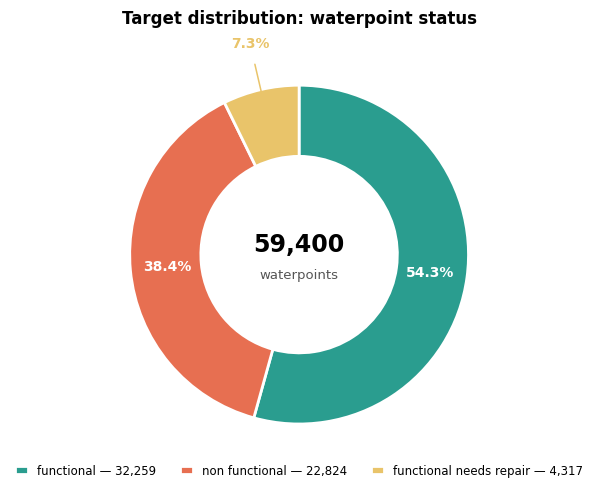

In [7]:
n = df["status_group"].value_counts()
p = (n / len(df) * 100).round(2)
STATS["target_counts"] = n.to_dict()
STATS["target_pct"] = p.to_dict()
STATS["majority_baseline_pct"] = float(p.max())
STATS["imbalance_ratio_major_minor"] = round(float(n.max() / n.min()), 2)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
# a ring rather than a full pie: the hole carries the row count, and the
# minority slice stays readable instead of collapsing to a sliver
# Define the class order and colors used later in the notebook.
ORDER = ["functional", "non functional", "functional needs repair"]
COLORS = ["#2A9D8F", "#E76F51", "#E9C46A"]

wedges, _, autotexts = ax.pie(
    [n[k] for k in ORDER],
    colors=COLORS,
    startangle=90,
    counterclock=False,
    pctdistance=0.78,
    autopct=lambda v: f"{v:.1f}%",
    wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2),
)
for t in autotexts:
    t.set(color="white", fontweight="bold", fontsize=10)

# the minority wedge is too narrow to hold its label, so move it outside
small = min(range(len(ORDER)), key=lambda i: n[ORDER[i]])
w = wedges[small]
mid = np.deg2rad((w.theta1 + w.theta2) / 2)
x, y = np.cos(mid), np.sin(mid)
autotexts[small].set(position=(x * 1.28, y * 1.28), color=COLORS[small], ha="center")
ax.annotate("", xy=(x * 0.82, y * 0.82), xytext=(x * 1.17, y * 1.17),
            arrowprops=dict(arrowstyle="-", color=COLORS[small], lw=1.1))

ax.text(0, 0.06, f"{len(df):,}", ha="center", va="center", fontsize=17, fontweight="bold")
ax.text(0, -0.12, "waterpoints", ha="center", va="center", fontsize=9.5, color="#555")
ax.legend(wedges, [f"{k} — {n[k]:,}" for k in ORDER], loc="upper center",
          bbox_to_anchor=(0.5, 0.03), ncol=3, frameon=False,
          fontsize=8.5, handlelength=1.1)
ax.set_title("Target distribution: waterpoint status", fontweight="bold", pad=14)
ax.set_aspect("equal")


print(f"Always guessing 'functional' scores {STATS['majority_baseline_pct']}%. "
      f"Any model has to beat that.")
print(f"Imbalance, majority to minority: {STATS['imbalance_ratio_major_minor']}:1")


## 4. Data Quality & Masked Anomalies

A thorough audit of data quality across three distinct dimensions:
- **4.1 Explicit Missing Values**: Standard `NaN` entries.
- **4.2 Disguised Missing Values**: Sentinel encodings masquerading as valid numbers.
- **4.3 Redundant Hierarchies & Constant Features**: Multicollinear categorical features and zero-variance columns.


### 4.1 Explicit Missing Values
We quantify explicit `NaN` values and visualize them in order of severity.
- `scheme_name` has nearly half its records missing (48.5%).
- `scheme_management`, `installer`, `funder`, `public_meeting`, and `permit` have between 5% and 7% missingness.


,n,pct
scheme_name,28810.0,48.50
scheme_management,3878.0,6.53
installer,3655.0,6.15
funder,3637.0,6.12
public_meeting,3334.0,5.61
permit,3056.0,5.14
subvillage,371.0,0.62
wpt_name,2.0,0.00


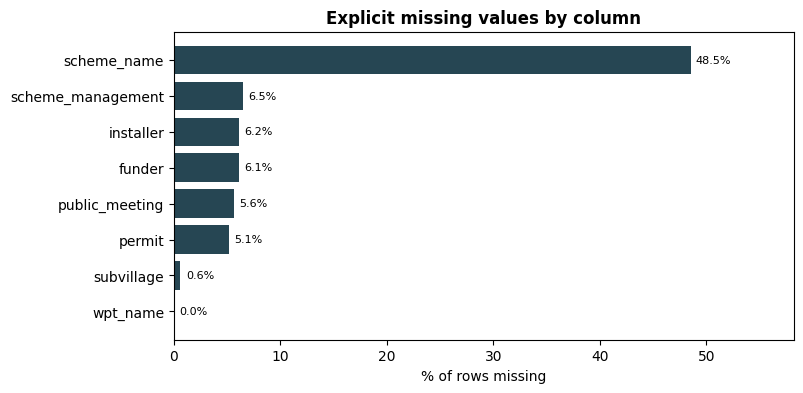

In [8]:
miss = df.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
STATS["missing"] = {c: {"n": int(v), "pct": round(v / len(df) * 100, 2)}
                    for c, v in miss.items()}

fig, ax = plt.subplots(figsize=(8, 4))
pcts = [STATS["missing"][c]["pct"] for c in miss.index][::-1]
ax.barh(list(miss.index)[::-1], pcts, color="#264653")
for i, v in enumerate(pcts):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("% of rows missing"); ax.set_xlim(0, max(pcts) * 1.2)
ax.set_title("Explicit missing values by column", fontweight="bold")

pd.DataFrame(STATS["missing"]).T


### 4.2 Disguised Missing Values — The Bigger Problem
In several numerical fields, "unknown" was recorded as `0`:
- **GPS Coordinates**: Tanzania is located south of the equator (latitudes $-1^\circ$ to $-12^\circ$). Therefore, waterpoints with coordinates near $(0, 0)$ represent GPS logging failures off the coast of Africa in the Gulf of Guinea ("Null Island"). All 1,812 rows with longitude 0 also have latitude near 0.
- **`population`**: Encodes missing as `0` (36.0%), but also frequently uses `1` (7,025 rows) as a placeholder. Together, **47.82%** of population entries are unusable.
- **`construction_year`**, **`gps_height`**, **`amount_tsh`**: Substantial percentages contain sentinel zeros (34%–70%).
- **`installer`**: Contains string `'0'` in 777 rows.

Treating these zeros as real measurements distorts scaling and distance calculations; they must be masked to `NaN` and flagged.


lon=0 and lat~0 co-occur in all 1812 rows -> one GPS-failure population, not two
population == 1 in 7,025 rows -> truly unusable share is 47.82%, not 35.99%
installer == '0' (a string) in 777 rows


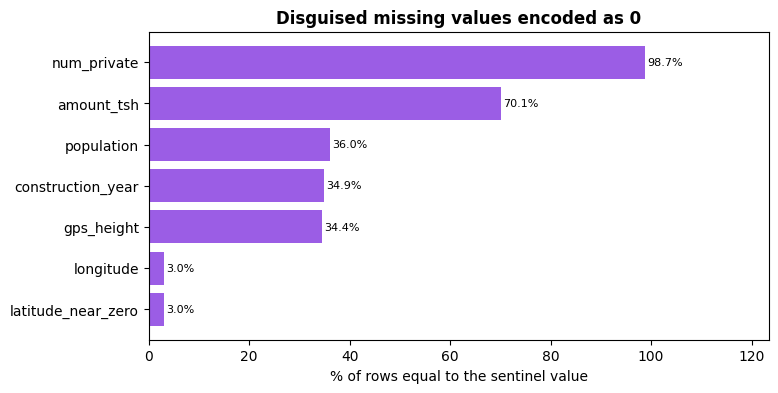

In [9]:
sent = {c: int((df[c] == 0).sum()) for c in
        ["num_private", "amount_tsh", "population", "construction_year", "gps_height"]}
sent["longitude"] = int((df["longitude"] == 0).sum())
# Tanzania lies south of the equator, so latitude at ~0 is a GPS failure
sent["latitude_near_zero"] = int((df["latitude"] > -0.1).sum())
STATS["sentinel_zeros"] = {c: {"n": v, "pct": round(v / len(df) * 100, 2)}
                           for c, v in sent.items()}

both = int(((df["longitude"] == 0) & (df["latitude"] > -0.1)).sum())
STATS["gps_zero_both"] = both

fig, ax = plt.subplots(figsize=(8, 4))
keys = list(sent)[::-1]; vals = [STATS["sentinel_zeros"][k]["pct"] for k in keys]
ax.barh(keys, vals, color="#9B5DE5")
for i, v in enumerate(vals):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("% of rows equal to the sentinel value"); ax.set_xlim(0, max(vals) * 1.25)
ax.set_title("Disguised missing values encoded as 0", fontweight="bold")

print(f"lon=0 and lat~0 co-occur in all {both} rows -> one GPS-failure "
      f"population, not two")

# zero is not the only sentinel
one = int((df["population"] == 1).sum())
inst0 = int((df["installer"].astype(str).str.strip() == "0").sum())
STATS["population_sentinels"] = {
    "zero_n": sent["population"], "one_n": one,
    "combined_unusable_pct": round((sent["population"] + one) / len(df) * 100, 2)}
STATS["installer_zero_string_n"] = inst0

print(f"population == 1 in {one:,} rows -> truly unusable share is "
      f"{STATS['population_sentinels']['combined_unusable_pct']}%, not "
      f"{STATS['sentinel_zeros']['population']['pct']}%")
print(f"installer == '0' (a string) in {inst0} rows")


### 4.3 Redundant Hierarchies & Zero-Information Columns
Multiple feature pairs encode the exact same underlying factor at varying granularities:
- `payment` and `payment_type`: **Exact 1:1 duplicate** ($V = 1.0$).
- `quantity` and `quantity_group`: **Exact 1:1 duplicate** ($V = 1.0$).
- `extraction_type`, `extraction_type_group`, and `extraction_type_class`: Near-identical hierarchical nesting.
- `recorded_by`: Has only 1 unique value across all 59,400 rows (**zero variance / zero information**).

Keeping exact 1:1 duplicates provides zero incremental information while inflating dimensionality.


In [10]:
HIERARCHIES = [
    ("extraction_type", "extraction_type_group", "extraction_type_class"),
    ("payment", "payment_type"), ("water_quality", "quality_group"),
    ("quantity", "quantity_group"), ("source", "source_type", "source_class"),
    ("waterpoint_type", "waterpoint_type_group"),
    ("management", "management_group"), ("region", "region_code"),
]

rows = []
for group in HIERARCHIES:
    for i, a in enumerate(group):
        for b in group[i + 1:]:
            one_to_one = bool(df.groupby(a, dropna=False)[b].nunique().max() == 1
                              and df.groupby(b, dropna=False)[a].nunique().max() == 1)
            rows.append({"a": a, "b": b, "one_to_one": one_to_one,
                         "cramers_v": round(cramers_v(df[a].astype(str),
                                                      df[b].astype(str)), 3)})

red = pd.DataFrame(rows).sort_values("cramers_v", ascending=False)
STATS["redundancy"] = {f"{r.a}~{r.b}": {"cramers_v": r.cramers_v,
                                        "one_to_one": r.one_to_one}
                       for r in red.itertuples()}
STATS["constant_columns"] = [c for c in df if df[c].nunique() <= 1]
print("constant columns (zero information):", STATS["constant_columns"])
red.head(10)


constant columns (zero information): ['recorded_by']


,a,b,one_to_one,cramers_v
0,extraction_type,extraction_type_group,False,1.0
1,extraction_type,extraction_type_class,False,1.0
2,extraction_type_group,extraction_type_class,False,1.0
3,payment,payment_type,True,1.0
4,water_quality,quality_group,False,1.0
5,quantity,quantity_group,True,1.0
6,source,source_type,False,1.0
7,source,source_class,False,1.0
8,source_type,source_class,False,1.0
9,waterpoint_type,waterpoint_type_group,False,1.0


## 5. What Actually Predicts Failure

### 5.1 Categorical Association Ranking (Cramér's V)
We compute bias-corrected Cramér's V against `status_group` for all categorical predictors (excluding noisy high-cardinality text columns).
- `quantity` (and its clone `quantity_group`) exhibits the strongest correlation ($V \approx 0.31$).
- Physical hardware traits (`waterpoint_type`, `extraction_type`) and socio-economic governance (`payment`) follow.


C:\Temp\ipykernel_9320\2144136040.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in df.select_dtypes("object") if c not in SKIP}


Text(0.5, 1.0, 'Strength of association with waterpoint status')

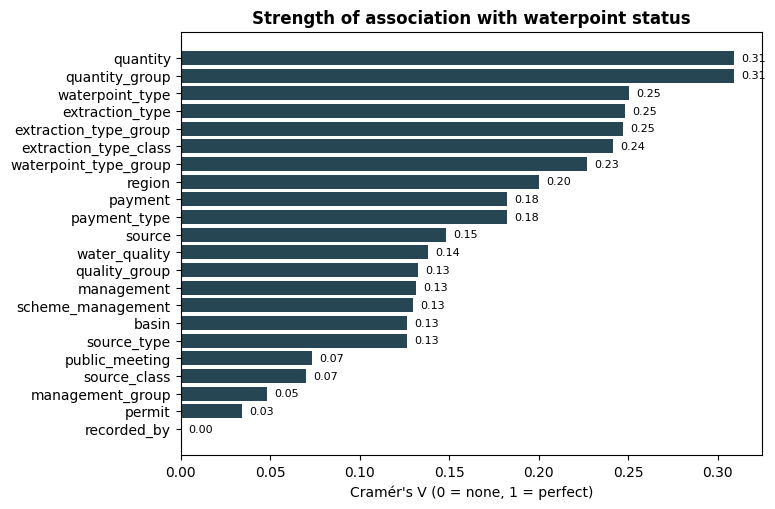

In [11]:
SKIP = {"status_group", "date_recorded", "wpt_name", "subvillage",
        "scheme_name", "ward", "funder", "installer", "lga"}
assoc = {c: round(cramers_v(df[c].astype(str), df["status_group"]), 4)
         for c in df.select_dtypes("object") if c not in SKIP}
assoc = dict(sorted(assoc.items(), key=lambda kv: -kv[1]))
STATS["cramers_v_vs_target"] = assoc

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ks = list(assoc)[::-1]
ax.barh(ks, [assoc[k] for k in ks], color="#264653")
for i, k in enumerate(ks):
    ax.text(assoc[k] + 0.004, i, f"{assoc[k]:.2f}", va="center", fontsize=8)
ax.set_xlabel("Cramér's V (0 = none, 1 = perfect)")
ax.set_title("Strength of association with waterpoint status", fontweight="bold")


### 5.2 Water Quantity — The Dominant Predictive Signal
Analyzing status composition across `quantity` categories:
- When water quantity is **`dry`**, **96.9% of waterpoints are non-functional**.
- When quantity is **`enough`**, **65.2% are functional**.
No other single variable separates functional from non-functional waterpoints with this magnitude.


dry -> 96.9% non functional
enough -> 65.2% functional


status_group,functional,non functional,functional needs repair
quantity,,,
dry,2.5,96.9,0.6
enough,65.2,27.5,7.2
insufficient,52.3,38.1,9.6
seasonal,57.4,32.3,10.3
unknown,27.0,71.2,1.8


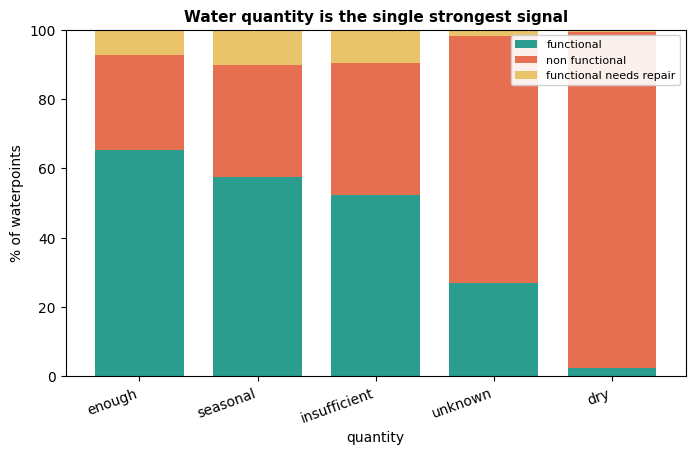

In [12]:
q = rate_by(df, "quantity")
STATS["quantity_breakdown"] = q.round(2).to_dict()

fig, ax = plt.subplots(figsize=(8, 4.5))
stacked(q, ax, "Water quantity is the single strongest signal",
        kind="bar", sort_asc=False, legend=True)
ax.set_xlabel("quantity"); ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
plt.xticks(rotation=20, ha="right")

print(f"dry -> {q.loc['dry', 'non functional']:.1f}% non functional")
print(f"enough -> {q.loc['enough', 'functional']:.1f}% functional")
q.round(1)


### 5.3 The Other Strong Drivers
We plot a 4-panel comparison of the top categorical drivers: `quantity`, `waterpoint_type`, `extraction_type_class`, and `payment`.
- Note `payment`: A socio-economic/governance variable, not an engineering or mechanical one.
- Waterpoints with **`pay annually`** achieve **75.2% functionality**, whereas waterpoints with **`never pay`** drop to **44.9%** (a 30 percentage point gap). User financial investment strongly correlates with operational maintenance.


pay annually -> 75.2% functional
never pay    -> 44.9% functional


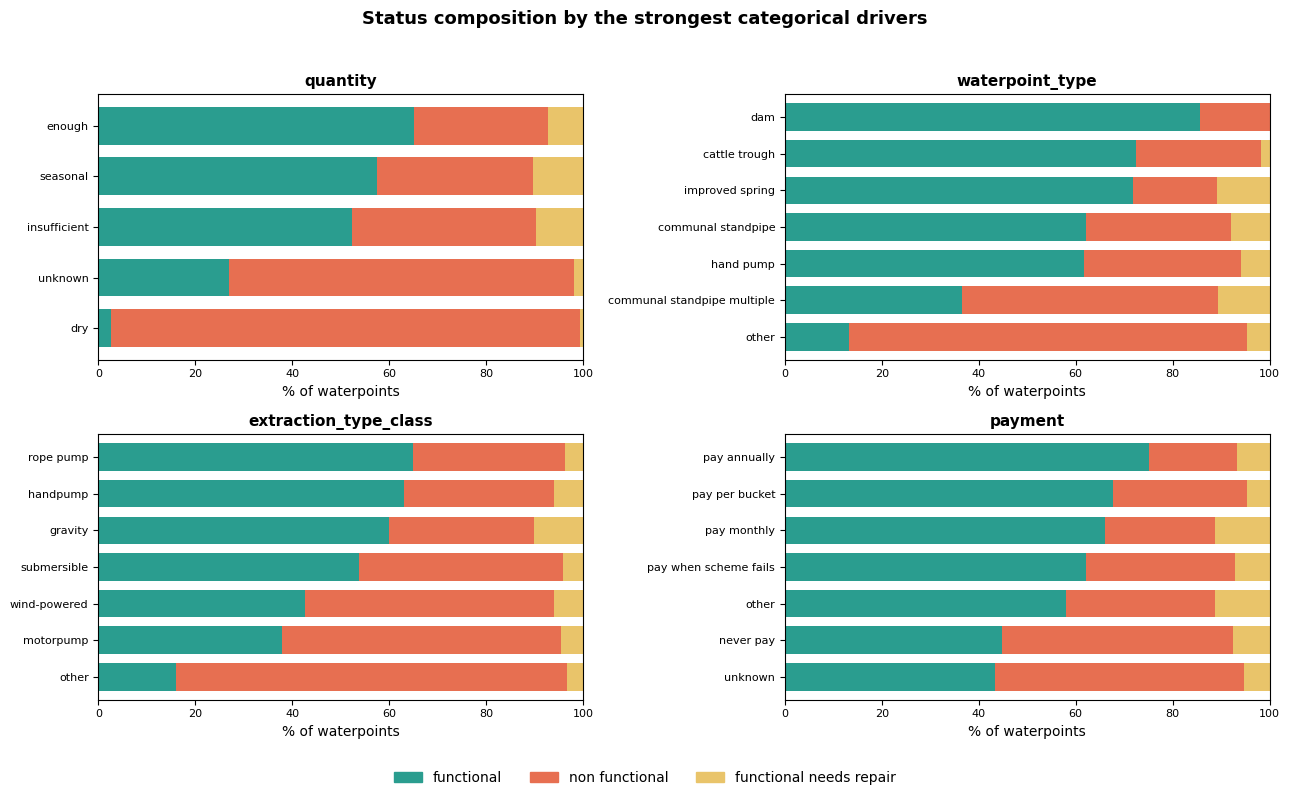

In [13]:
PANELS = ["quantity", "waterpoint_type", "extraction_type_class", "payment"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, f in zip(axes.ravel(), PANELS):
    stacked(rate_by(df, f), ax, f)
    ax.tick_params(labelsize=8)
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS],
           ORDER, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Status composition by the strongest categorical drivers",
             fontweight="bold", fontsize=13)
fig.tight_layout(rect=[0, 0.05, 1, 0.96])

pay = rate_by(df, "payment")
STATS["payment_breakdown"] = pay.round(2).to_dict()
print(f"pay annually -> {pay.loc['pay annually', 'functional']:.1f}% functional")
print(f"never pay    -> {pay.loc['never pay', 'functional']:.1f}% functional")


## 6. Numeric Feature Diagnostics & Anomaly Detection

### 6.1 Age — The Strongest Numeric Signal
Calculating the true age of waterpoints requires two critical rules:
1. Filter out `construction_year == 0` first (sentinel encoding, not year zero).
2. Subtract integer years (`survey_year - construction_year`), avoiding datetime parsing mistakes.

Waterpoint functionality steadily degrades with age:
- Waterpoints $\le 5$ years old: **71.51% functional**.
- Waterpoints $\ge 30$ years old: **31.73% functional** (a 40-point drop).
- A small number of negative age values (9 rows) reflect data entry mistakes where construction was recorded after inspection.


C:\Temp\ipykernel_9320\2887719600.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


median age by status: {'functional': 9.0, 'functional needs repair': 14.0, 'non functional': 18.0}
functional rate: 71.51% at age<=5 -> 31.73% at age>=30
9 rows have a negative age (entry errors)


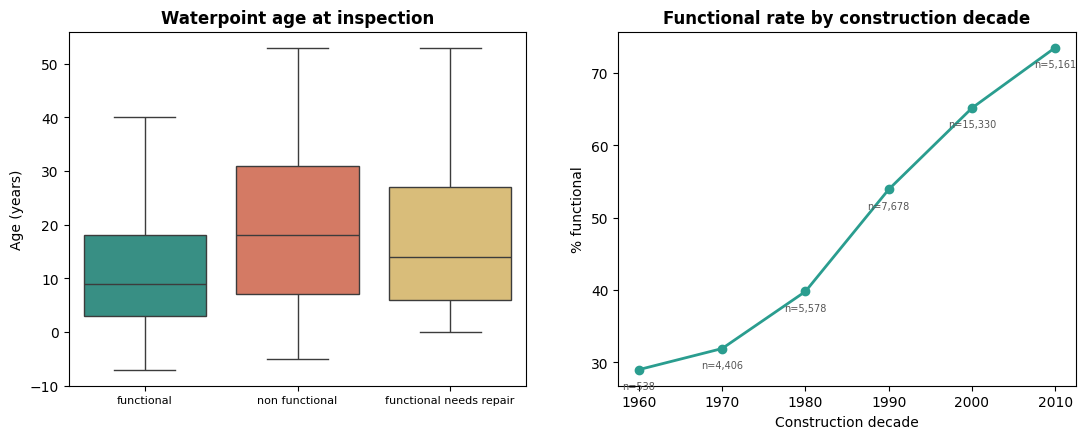

In [14]:
d = df.copy()
d["date_recorded"] = pd.to_datetime(d["date_recorded"])
valid = d[d["construction_year"] > 0].copy()
valid["age"] = valid["date_recorded"].dt.year - valid["construction_year"]

STATS["age_median_by_status"] = valid.groupby("status_group")["age"].median().to_dict()
STATS["negative_age_n"] = int((valid["age"] < 0).sum())

STATS["functional_pct_age_le_5"] = round(
    float((valid.loc[valid["age"] <= 5, "status_group"] == "functional").mean() * 100), 2)
STATS["functional_pct_age_ge_30"] = round(
    float((valid.loc[valid["age"] >= 30, "status_group"] == "functional").mean() * 100), 2)

valid["decade"] = valid["construction_year"] // 10 * 10
dec = pd.crosstab(valid["decade"], valid["status_group"], normalize="index") * 100
decn = valid["decade"].value_counts().sort_index()
STATS["functional_pct_by_decade"] = {
    str(i): {"n": int(decn[i]), "functional_pct": round(float(dec.loc[i, "functional"]), 2)}
    for i in dec.index}

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4.6))
PALETTE = dict(zip(ORDER, COLORS))
sns.boxplot(
    data=valid,
    x="status_group",
    y="age",
    order=ORDER,
    palette=PALETTE,
    ax=ax0,
    showfliers=False
)
ax0.set(xlabel="", ylabel="Age (years)")
ax0.set_title("Waterpoint age at inspection", fontweight="bold")
ax0.tick_params(axis="x", labelsize=8)

ax1.plot(dec.index, dec["functional"], marker="o", color="#2A9D8F", lw=2)
ax1.set(xlabel="Construction decade", ylabel="% functional")
ax1.set_title("Functional rate by construction decade", fontweight="bold")
for i in dec.index:
    ax1.annotate(f"n={decn[i]:,}", (i, dec.loc[i, "functional"]),
                 textcoords="offset points", xytext=(0, -14),
                 ha="center", fontsize=7, color="#555")


print("median age by status:", STATS["age_median_by_status"])
print(f"functional rate: {STATS['functional_pct_age_le_5']}% at age<=5 -> "
      f"{STATS['functional_pct_age_ge_30']}% at age>=30")
print(f"{STATS['negative_age_n']} rows have a negative age (entry errors)")


### 6.2–6.3 Distributions, Extreme Tails & Fabricated Maxima
`amount_tsh` peaks at 350,000 with extreme skewness (57.8). We test whether these values reflect true measurements or corrupt entries through four diagnostic checks:
1. **Max-to-99th Percentile Ratio**: `amount_tsh` max is $30.7\times$ the 99th percentile; `population` max is $12.2\times$.
2. **Round Number Heuristic**: 94.0% of non-zero `amount_tsh` values are divisible by 10 (estimates rather than exact readings).
3. **Repeated Large Values**: 117,000 appears 7 times, all in Iringa; 100,000 appears 3 times across multiple regions (copied records).
4. **Physical Plausibility**: 2 rows with `amount_tsh >= 100,000` and rows with `population >= 9,000` are associated with simple hand pumps (serving at most a few hundred people).

> **Verdict:** Both tails are contaminated by data entry errors. Models should winsorize at the 99th percentile or apply $\log(1+x)$.


In [15]:
for col in ["amount_tsh", "population"]:
    nz = df[col][df[col] > 0]
    s = {"n_nonzero": len(nz), "median_nonzero": float(nz.median()),
         "p99": float(nz.quantile(0.99)), "max": float(nz.max()),
         "skew": round(float(df[col].skew()), 2)}
    s["max_over_p99"] = round(s["max"] / s["p99"], 1)
    # check 2 — measurements are not round numbers; guesses are
    s.update({f"divisible_by_{k}_pct": round(float((nz % k == 0).mean() * 100), 1)
              for k in (10, 100, 500)})
    STATS[col] = s
    print(f"{col:11s} median={s['median_nonzero']:>8,.0f}  p99={s['p99']:>9,.0f}  "
          f"max={s['max']:>9,.0f} ({s['max_over_p99']}x p99)  "
          f"skew={s['skew']:>6}  divisible-by-10: {s['divisible_by_10_pct']}%")


amount_tsh  median=     250  p99=   11,400  max=  350,000 (30.7x p99)  skew= 57.81  divisible-by-10: 94.0%
population  median=     150  p99=    2,500  max=   30,500 (12.2x p99)  skew= 12.66  divisible-by-10: 63.4%


In [16]:
# check 3 — a five-digit value repeating across rows was copied, not measured
big = df[df["amount_tsh"] >= 100_000]
rep = big["amount_tsh"].value_counts()
STATS["amount_tsh_repeated_large_values"] = {
    str(int(v)): {"n_rows": int(k),
                  "regions": sorted(big.loc[big["amount_tsh"] == v, "region"].unique())}
    for v, k in rep[rep > 1].items()}
for v, r in STATS["amount_tsh_repeated_large_values"].items():
    print(f"{int(v):,} appears in {r['n_rows']} rows, all in {r['regions']}"
          f" -> a copied entry, not {r['n_rows']} independent measurements")

# check 4 — is the row physically possible?
hand = big[big["waterpoint_type"].str.contains("hand pump", case=False)]
STATS["amount_tsh_ge_100k"] = {"n_rows": len(big),
                               "n_from_river": int((big["source"] == "river").sum()),
                               "n_hand_pump": len(hand)}
print(f"\namount_tsh >= 100,000 — {len(big)} rows, of which "
      f"{STATS['amount_tsh_ge_100k']['n_from_river']} draw from a river (plausible) "
      f"and {len(hand)} sit on a hand pump (impossible):")
big[["id", "amount_tsh", "population", "source", "waterpoint_type",
     "quantity", "region", "status_group"]]


117,000 appears in 7 rows, all in ['Iringa'] -> a copied entry, not 7 independent measurements
100,000 appears in 3 rows, all in ['Pwani', 'Rukwa', 'Ruvuma'] -> a copied entry, not 3 independent measurements

amount_tsh >= 100,000 — 16 rows, of which 13 draw from a river (plausible) and 2 sit on a hand pump (impossible):


,id,amount_tsh,population,source,waterpoint_type,quantity,region,status_group
3228,69674,100000.0,250,shallow well,hand pump,enough,Ruvuma,functional
5558,15801,117000.0,60,river,communal standpipe,enough,Iringa,functional
6591,10996,100000.0,315,machine dbh,hand pump,enough,Rukwa,functional needs repair
9917,15191,120000.0,120,river,communal standpipe,enough,Kilimanjaro,functional
9961,54154,138000.0,587,river,communal standpipe,enough,Pwani,functional
10615,71707,117000.0,150,river,communal standpipe multiple,enough,Iringa,functional
10812,41564,350000.0,886,machine dbh,communal standpipe,insufficient,Singida,functional
22191,4128,250000.0,80,river,communal standpipe,enough,Pwani,functional
22817,7860,200000.0,800,river,communal standpipe,enough,Tanga,functional
37459,38117,117000.0,20,river,communal standpipe,enough,Iringa,functional


In [17]:
pop_big = df[df["population"] >= 9000]
print("population >= 9,000 — note the maximum is a hand pump, which serves a "
      "few hundred people at most:")
pop_big[["id", "amount_tsh", "population", "source", "waterpoint_type",
         "quantity", "region", "status_group"]]


population >= 9,000 — note the maximum is a hand pump, which serves a few hundred people at most:


,id,amount_tsh,population,source,waterpoint_type,quantity,region,status_group
12784,33117,0.0,9865,machine dbh,communal standpipe,enough,Dar es Salaam,non functional
13725,18520,0.0,9500,machine dbh,other,enough,Arusha,functional needs repair
14308,49354,0.0,15300,machine dbh,communal standpipe,insufficient,Manyara,functional needs repair
30231,63349,0.0,10000,shallow well,hand pump,enough,Mara,functional
30537,12169,0.0,30500,shallow well,hand pump,insufficient,Tanga,functional
31363,56570,30.0,10000,machine dbh,hand pump,enough,Rukwa,functional
31473,16664,50.0,9000,machine dbh,communal standpipe multiple,enough,Singida,non functional
48725,17459,0.0,9000,dam,communal standpipe multiple,enough,Mara,functional
51398,30750,50.0,11463,river,communal standpipe,enough,Pwani,functional
51919,69166,8000.0,9000,machine dbh,other,enough,Rukwa,non functional


## 7. Geography & Spatial Patterns

### 7.1 Regional Disparities
Waterpoint functionality varies drastically by geographic region:
- **Iringa**: **78.2% functional**
- **Lindi**: **29.8% functional**
- This **48.47 percentage point spread** exceeds the impact of nearly all mechanical variables. Discarding raw coordinates in favor of coarse administrative region labels discards localized spatial trends.


Iringa (78.2% functional) to Lindi (29.8%) is a 48.47pp spread


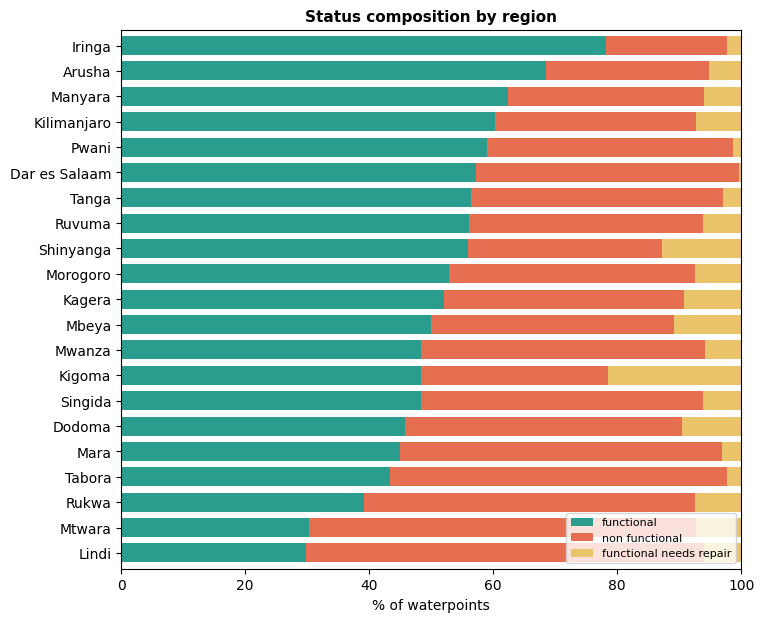

In [18]:
reg = rate_by(df, "region")
best, worst = reg["functional"].idxmax(), reg["functional"].idxmin()
STATS["region_functional_pct"] = reg["functional"].round(2).to_dict()
STATS["region_spread_pp"] = round(float(reg.loc[best, "functional"]
                                        - reg.loc[worst, "functional"]), 2)

fig, ax = plt.subplots(figsize=(8, 7))
stacked(reg, ax, "Status composition by region", legend=True)
ax.legend(fontsize=8, loc="lower right")

print(f"{best} ({reg.loc[best, 'functional']:.1f}% functional) to "
      f"{worst} ({reg.loc[worst, 'functional']:.1f}%) is a "
      f"{STATS['region_spread_pp']}pp spread")

geo = df[(df["longitude"] != 0) & (df["latitude"] < -0.1)]
STATS["geo_plotted_n"] = len(geo)
STATS["geo_dropped_invalid_n"] = len(df) - len(geo)


### 8.2 Geospatial Mapping Across Tanzania
We render a comprehensive geospatial visualization using Basemap:
- Reconstruct regional boundaries via 1-NN Voronoi tessellation clipped to Tanzanian landmass.
- Overlay 57,588 validated GPS waterpoints color-coded by functionality.
- The map reveals localized spatial clustering of pump failures independent of regional borders.


1,812 rows dropped for invalid GPS


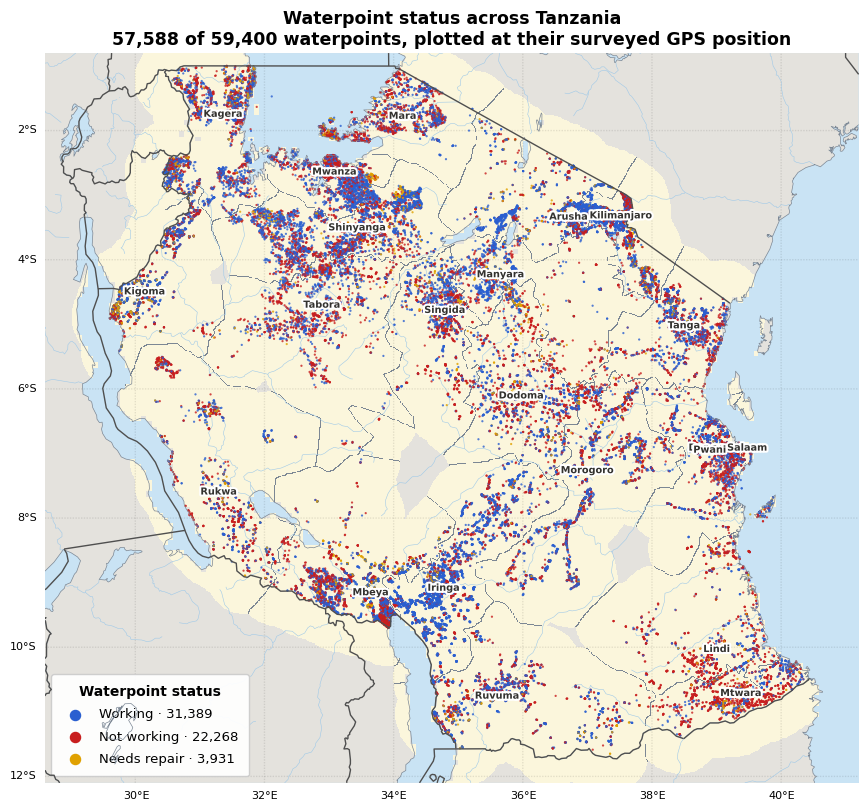

In [19]:
# Real geography — coastline, lakes, rivers, national borders — from the
# datasets bundled with basemap-data. Region divisions are not in there, so
# they are reconstructed: each grid cell takes the region of its nearest
# waterpoint, then maskoceans cuts the tint back to real land.

PRIMARY = {"functional": "#2A5FD0", "functional needs repair": "#E0A100",
           "non functional": "#C81E1E"}
PLAIN = {"functional": "Working", "functional needs repair": "Needs repair",
         "non functional": "Not working"}

LON0, LON1, LAT0, LAT1 = 28.6, 41.2, -12.1, -0.8
GRID, REACH = 900, 0.60

fig, ax = plt.subplots(figsize=(10.5, 10))
m = Basemap(projection="cyl", resolution="i", ax=ax, llcrnrlon=LON0,
            urcrnrlon=LON1, llcrnrlat=LAT0, urcrnrlat=LAT1)
m.drawmapboundary(fill_color="#C9E3F4", linewidth=0)
m.fillcontinents(color="#E4E2DD", lake_color="#C9E3F4")

xy = geo[["longitude", "latitude"]].to_numpy()
gx, gy = np.meshgrid(np.linspace(LON0, LON1, GRID), np.linspace(LAT0, LAT1, GRID))
grid = np.c_[gx.ravel(), gy.ravel()]

codes = {r: i for i, r in enumerate(sorted(geo["region"].unique()))}
reg = np.array([codes[r] for r in KNeighborsClassifier(1)
                .fit(xy, geo["region"].to_numpy()).predict(grid)]).reshape(gx.shape)
dist = NearestNeighbors(n_neighbors=1).fit(xy).kneighbors(grid)[0]
inside = (dist.ravel() < REACH).reshape(gx.shape)

edge = np.zeros_like(inside)
edge[:-1]    |= reg[:-1] != reg[1:]
edge[:, :-1] |= reg[:, :-1] != reg[:, 1:]

land = np.asarray(maskoceans(gx, gy, np.where(inside, 1.0, np.nan),
                             resolution="h", inlands=True).filled(np.nan))

ext = (LON0, LON1, LAT0, LAT1)
ax.imshow(land, extent=ext, origin="lower", vmin=0, vmax=1, zorder=2,
          cmap=ListedColormap(["#FBF6DC"]), interpolation="nearest")
ax.imshow(np.where(np.isfinite(land) & edge, 1.0, np.nan), extent=ext,
          origin="lower", vmin=0, vmax=1, zorder=3,
          cmap=ListedColormap(["#7C8794"]), interpolation="nearest")

# random order, so a dense patch shows its actual mix rather than whichever
# class happened to be drawn last
sh = geo.sample(frac=1, random_state=0)
ax.scatter(sh["longitude"], sh["latitude"], s=2.6, zorder=5, linewidths=0,
           alpha=0.8, c=[PRIMARY[k] for k in sh["status_group"]])

for k in ORDER:
    ax.scatter([], [], s=2.6, c=PRIMARY[k],
               label=f"{PLAIN[k]} · {geo['status_group'].eq(k).sum():,}")

m.drawrivers(linewidth=0.4, color="#9FC9E8", zorder=4)
m.drawcoastlines(linewidth=0.5, color="#7C8794", zorder=6)
m.drawcountries(linewidth=1.0, color="#4F4F4F", zorder=6)
m.drawparallels(range(-12, 0, 2), labels=[1, 0, 0, 0], fontsize=8, color="#00000018")
m.drawmeridians(range(30, 42, 2), labels=[0, 0, 0, 1], fontsize=8, color="#00000018")

for r, g in geo.groupby("region"):
    ax.text(g["longitude"].median(), g["latitude"].median(), r, fontsize=7,
            fontweight="bold", ha="center", va="center", zorder=8, color="#33322F",
            path_effects=[pe.withStroke(linewidth=3, foreground="white")])

leg = ax.legend(loc="lower left", frameon=True, framealpha=0.94, fontsize=9.5,
                markerscale=4.5, borderpad=0.8, labelspacing=0.7,
                title="Waterpoint status")
leg.get_title().set_fontweight("bold")
ax.set_title("Waterpoint status across Tanzania\n"
             f"{len(geo):,} of {len(df):,} waterpoints, plotted at their "
             "surveyed GPS position", fontweight="bold", fontsize=12.5)

print(f"{STATS['geo_dropped_invalid_n']:,} rows dropped for invalid GPS")
